# LeetCode #78: Subsets

https://leetcode.com/problems/subsets/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(2^n \cdot n)$ | $O(2^n \cdot n)$ |
| **Optimal: Backtracking ★** | $O(2^n \cdot n)$ | $O(n)$ |

---

## Understanding the Methods

### Brute Force
Use nested loops or bit-masking over all $2^n$ possible bitmasks to decide which elements to include in each subset. Clear but produces all subsets via arithmetic rather than structured recursion, and builds all $2^n$ lists at once in memory.

### Optimal: Backtracking ★
At each recursion level, snapshot the current path into the result, then iterate over the remaining elements from index `start` onward — each element either extends the current combination or is skipped by advancing `start`. This visits each of the $2^n$ subsets exactly once with no duplication logic needed.

**Why this is better than Brute Force:** Generating subsets incrementally (adding one element per recursion level) means the running path is reused for every subset, keeping auxiliary memory at $O(n)$ instead of $O(2^n \cdot n)$.

**Constraints:**
* 1 <= nums.length <= 10
* -10 <= nums[i] <= 10
* All the numbers of nums are unique

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<IList<int>> Subsets(int[] nums) {
        var result = new List<IList<int>>();
        Backtrack(nums, 0, new List<int>(), result);
        return result;
    }

    private void Backtrack(int[] nums, int start, List<int> path, IList<IList<int>> result) {
        // Every prefix of the current path is a valid subset — record it
        result.Add(new List<int>(path));
        for (int i = start; i < nums.Length; i++) {
            path.Add(nums[i]);
            // Recurse with i+1 so each element is used at most once per subset
            Backtrack(nums, i + 1, path, result);
            // Undo the choice to explore subsets that omit nums[i]
            path.RemoveAt(path.Count - 1);
        }
    }
}

### Python

In [ ]:
class Solution:
    def subsets(self, nums: list[int]) -> list[list[int]]:
        result = []

        def backtrack(start: int, path: list[int]) -> None:
            # Every prefix of the current path is a valid subset — record it
            result.append(list(path))
            for i in range(start, len(nums)):
                path.append(nums[i])
                # Recurse with i+1 so each element is used at most once per subset
                backtrack(i + 1, path)
                # Undo the choice to explore subsets that omit nums[i]
                path.pop()

        backtrack(0, [])
        return result

### Go

In [ ]:
func subsets(nums []int) [][]int {
    result := [][]int{}
    path := []int{}

    var backtrack func(start int)
    backtrack = func(start int) {
        // Every prefix of the current path is a valid subset — record it
        subset := make([]int, len(path))
        copy(subset, path)
        result = append(result, subset)
        for i := start; i < len(nums); i++ {
            path = append(path, nums[i])
            // Recurse with i+1 so each element is used at most once per subset
            backtrack(i + 1)
            // Undo the choice to explore subsets that omit nums[i]
            path = path[:len(path)-1]
        }
    }
    backtrack(0)
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn subsets(nums: Vec<i32>) -> Vec<Vec<i32>> {
        let mut result = Vec::new();
        let mut path = Vec::new();
        Self::backtrack(&nums, 0, &mut path, &mut result);
        result
    }

    fn backtrack(nums: &[i32], start: usize, path: &mut Vec<i32>, result: &mut Vec<Vec<i32>>) {
        // Every prefix of the current path is a valid subset — record it
        result.push(path.clone());
        for i in start..nums.len() {
            path.push(nums[i]);
            // Recurse with i+1 so each element is used at most once per subset
            Self::backtrack(nums, i + 1, path, result);
            // Undo the choice to explore subsets that omit nums[i]
            path.pop();
        }
    }
}

## Example Scenarios

### 1. Common Case
**Input:** nums = [1, 2, 3]
The recursion records [] first, then extends: [1] → [1,2] → [1,2,3], backtrack → [1,3]; then [2] → [2,3]; then [3]. Every node visited is itself a recorded subset, giving $2^3 = 8$ subsets including the empty set.

### 2. Slightly Complex
**Input:** nums = [0, 1, 2]
A zero element is handled exactly like any other value — the recursion branches on index, not on the value — so the 8 subsets are [], [0], [0,1], [0,1,2], [0,2], [1], [1,2], [2].

### 3. Edge Case: Time Factor
**Input:** nums = [1, 2, …, 10] (n = 10, maximum)
Each added element doubles the subset count, so $2^{10} = 1024$ subsets are generated with recursion depth at most 10. Summed copy cost is $\sum_{k=0}^{10}\binom{10}{k}k = 5120$ element copies, confirming $O(n \cdot 2^n)$ time.

### 4. Edge Case: Space Factor
**Input:** nums = [1, 2, …, 10]
The live `path` holds at most 10 elements and stack depth is at most 10, so auxiliary memory is $O(n)$. The 1024 output subsets are the dominant memory consumer.

### 5. Almost-Impossible but Plausible
**Input:** nums = [-10, -5, 0, 5, 10]
All $2^5 = 32$ subsets are generated. Negative values and zero participate identically because the backtracking only ever inspects indices, never the values themselves.


## Infographic

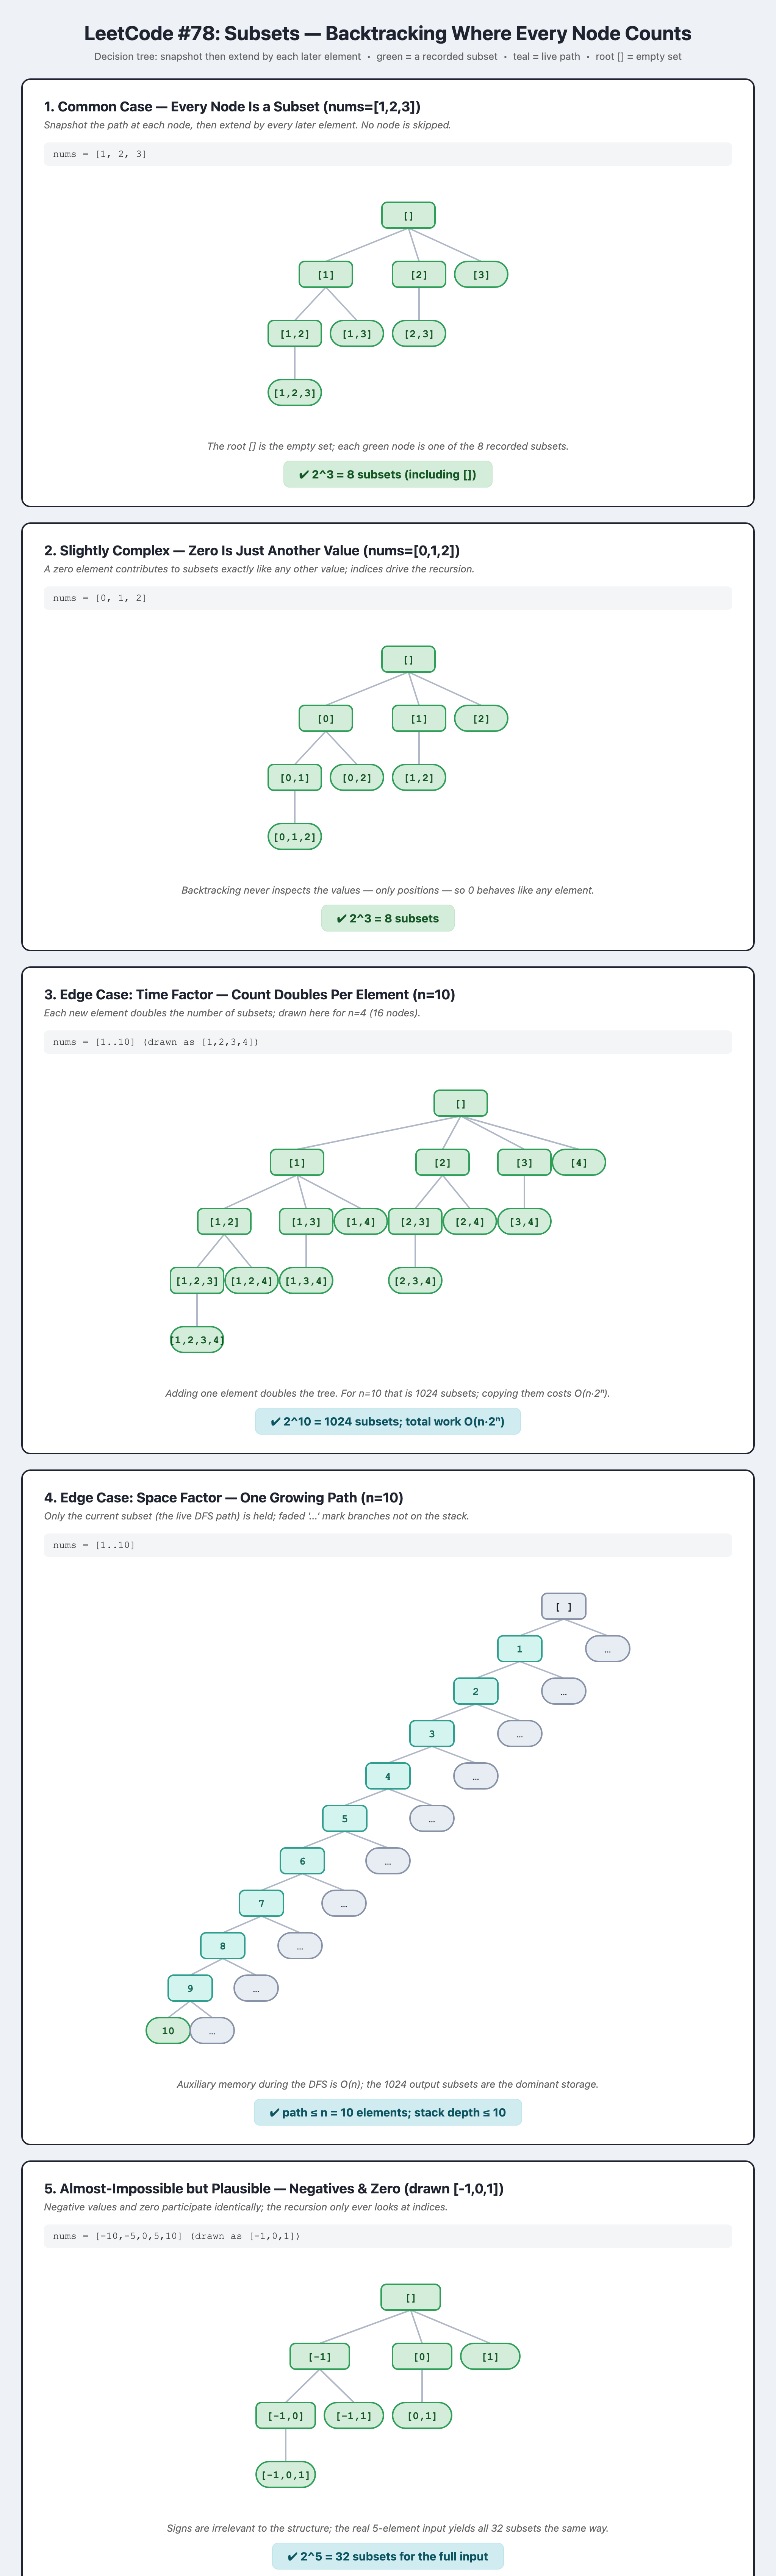